## Assignment 4 - ARIMA(X) & TBATS - Skeleton

In [13]:
# Import relevant modules
import pandas as pd
import numpy as np
from numpy import fft
import pmdarima as pm
from matplotlib import pyplot as plt
import seaborn as sns
from tbats import TBATS
import time 
import statsmodels.api as sm
import pickle
from dateutil.parser import parse

def mean_absolute_percentage_error(actual,forecast):
    mape = np.mean(abs((actual-forecast)/actual)) * 100
    return mape

In [14]:
#Helper function for MSIS
def calculate_MSIS(time_series_true, prediction_interval, horizon, alpha):
                    
        out_of_sample_true = time_series_true[-horizon:]
        out_of_sample_predict_int = prediction_interval[-horizon:]
        out_of_sample_predict_int_upper = out_of_sample_predict_int.T[0].tolist()
        out_of_sample_predict_int_lower = out_of_sample_predict_int.T[1].tolist()
                
        denominator_calc = [upper-lower + 2/alpha*(lower-true) if true < lower else upper-lower + 2/alpha*(true-upper) for (upper, lower, true) in zip(out_of_sample_predict_int_upper, out_of_sample_predict_int_lower, out_of_sample_true)]
        denominator_calc = sum(denominator_calc)
        
        in_sample_true_1 = time_series_true[horizon:-horizon]
        in_sample_true_2 = time_series_true[:-2*horizon]
        
        divisor_calc = 1/(len(time_series_true) - 2*horizon) * sum([np.abs(y_1-y_2) for (y_1, y_2) in zip(in_sample_true_1, in_sample_true_2)])
        
        return (1/horizon * denominator_calc / divisor_calc)

In [15]:
# Step 1: Load data and split data
gasoline = pd.read_csv("gasoline.csv")
gasoline = gasoline.set_index(keys = ['index'])

In [16]:
# Split in train and test set. test is from 2005 onwards, gas_test_2005 is only the year 2005. Train is everything before

gas_train = gasoline.loc['1991':'2005']
gas_test = gasoline.loc['2006':'2017']
gas_test_2005 = gasoline.loc['2005': '2006']
index_2005 = gas_test_2005.index

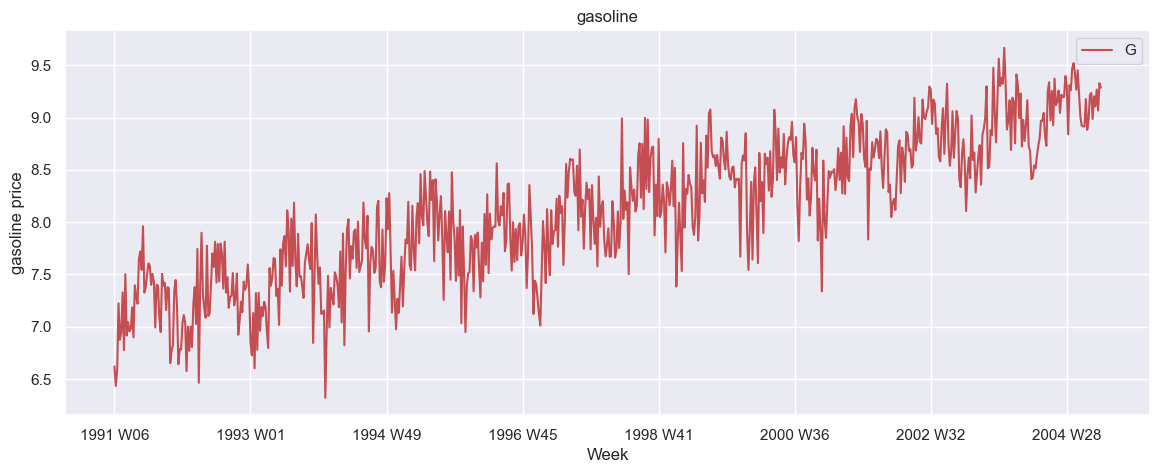

In [17]:
# Plot time-series
sns.set(rc={'figure.figsize':(14, 5)})
plot_all = gas_train.plot(style = 'r',title = 'gasoline')
plot_all.set_xlabel("Week")
plot_all.set_ylabel("gasoline price")
plot_all.legend('Gasoline price');

Auto_arima takes a lot of time to run. Therefore, we saved the model and you can just load it. It is essential to understand this part though. 
### *DO NOT RUN IT!*

In [ ]:
# Step 2: Auto_arima, Load and forecast

# DO NOT RUN!!

# model = pm.auto_arima(gas_train, max_p= 2, max_q = 2, trace =True, m = 52)
# model.fit(gas_train)
# file = open("arima_new.p", "wb")
# pickle.dump(model, file)
# file.close()

In [18]:
# Load the auto arima model
model = pickle.load(open("arima.p", "rb"))
print(model)
model.summary()

c:\Users\Administrator\Desktop\training_materials\3322 - Time Series Forecasts\.venv\Lib\site-packages\pmdarima\arima\arima.py:859: UserWarning: You've deserialized an ARIMA from a version (1.8.5) that does not match your installed version of pmdarima (2.0.4). This could cause unforeseen behavior.
  warnings.warn("You've deserialized an ARIMA from a version (%s) "


 ARIMA(0,1,2)(0,0,2)[52]          


<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                      
==========================================================================================
Dep. Variable:                                  y   No. Observations:                  726
Model:             SARIMAX(0, 1, 2)x(0, 0, 2, 52)   Log Likelihood                -167.110
Date:                            Wed, 14 Oct 2026   AIC                            344.220
Time:                                    04:45:00   BIC                            367.151
Sample:                                         0   HQIC                           353.070
                                            - 726                                         
Covariance Type:                              opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.8602      0.039    -22.257      0.000      -0.936      -0.784
ma.L2          0.0815      0.039      2.089      0.037       0.005       0.158
ma.S.L52       0.1915      0.038      5.004      0.000       0.116       0.267
ma.S.L104      0.1293      0.042      3.113      0.002       0.048       0.211
sigma2         0.0923      0.005     19.910      0.000       0.083       0.101
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):                 5.30
Prob(Q):                              0.97   Prob(JB):                         0.07
Heteroskedasticity (H):               0.72   Skew:                            -0.17
Prob(H) (two-sided):                  0.01   Kurtosis:                         3.23
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

c:\Users\Administrator\Desktop\training_materials\3322 - Time Series Forecasts\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\Administrator\Desktop\training_materials\3322 - Time Series Forecasts\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


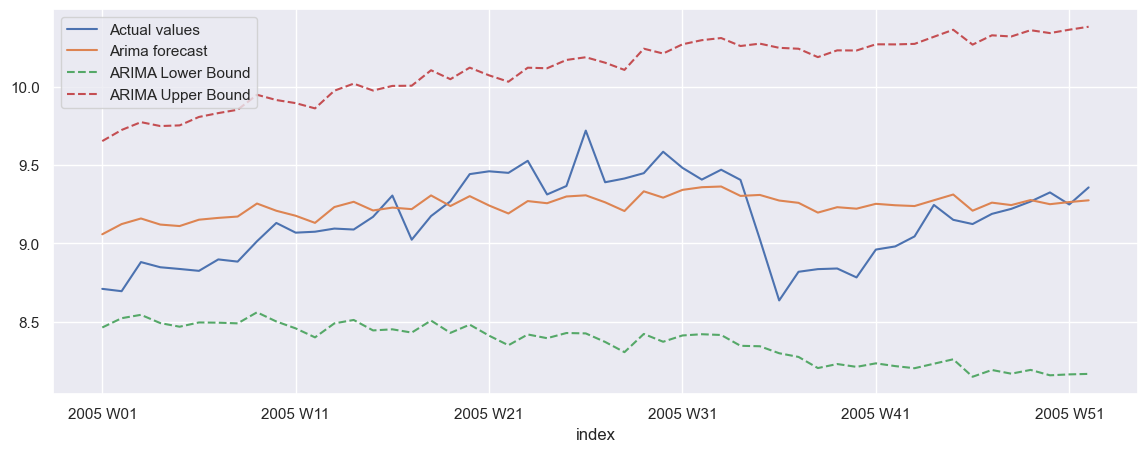

In [19]:
# Generate forecasts

fitted_data, confidence_int_ARIMA = model.predict(n_periods = len(gas_test_2005), return_conf_int = True, alpha = 0.05)
arima_forecast = pd.DataFrame(data = fitted_data, index = index_2005)

# Plot forecasts
combined_ARIMA = pd.concat([gas_test_2005,arima_forecast], axis = 1)
combined_ARIMA.columns = ['Actual values','Arima forecast']

# Add Confidence Intervals
combined_ARIMA['ARIMA Lower Bound'] = confidence_int_ARIMA.T[0].tolist()
combined_ARIMA['ARIMA Upper Bound'] = confidence_int_ARIMA.T[1].tolist()
combined_ARIMA.plot(style=['-', '-', '--', '--']);

In [21]:
# Step 3: Fit a TBATS model on gasoline

# Check which seasonal period makes sense
start_time_tbats = time.time()

# CODE HERE IN seasonal_periods
tbats_model = TBATS(seasonal_periods = [52], use_box_cox = False, use_arma_errors =False)
fitted_model = tbats_model.fit(gas_train)

end_time_tbats = time.time()
total_time_taken = end_time_tbats - start_time_tbats
print("Total time taken: " + str(total_time_taken))

print(fitted_model.summary())

# AIC
print(fitted_model.aic)

c:\Users\Administrator\Desktop\training_materials\3322 - Time Series Forecasts\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\Administrator\Desktop\training_materials\3322 - Time Series Forecasts\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\Administrator\Desktop\training_materials\3322 - Time Series Forecasts\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


Total time taken: 33.99654221534729
Use Box-Cox: False
Use trend: True
Use damped trend: True
Seasonal periods: [52.]
Seasonal harmonics [7]
ARMA errors (p, q): (0, 0)
Smoothing (Alpha): -0.028798
Trend (Beta): 0.030440
Damping Parameter (Phi): 0.800000
Seasonal Parameters (Gamma): [ 7.99828713e-08 -4.00979538e-08]
AR coefficients []
MA coefficients []
Seed vector [ 7.04145072e+00  9.06012276e-03 -2.74321213e-01 -1.81712898e-02
 -9.49490805e-02 -3.64031439e-02 -4.51485403e-02 -5.63138127e-02
  2.70567663e-02  5.56626611e-03 -3.95386669e-02  1.32580869e-02
  1.78469668e-02 -3.56526604e-03  4.31706895e-02  2.94984288e-02]

AIC 2919.911045
2919.9110450885364


<Axes: xlabel='index'>

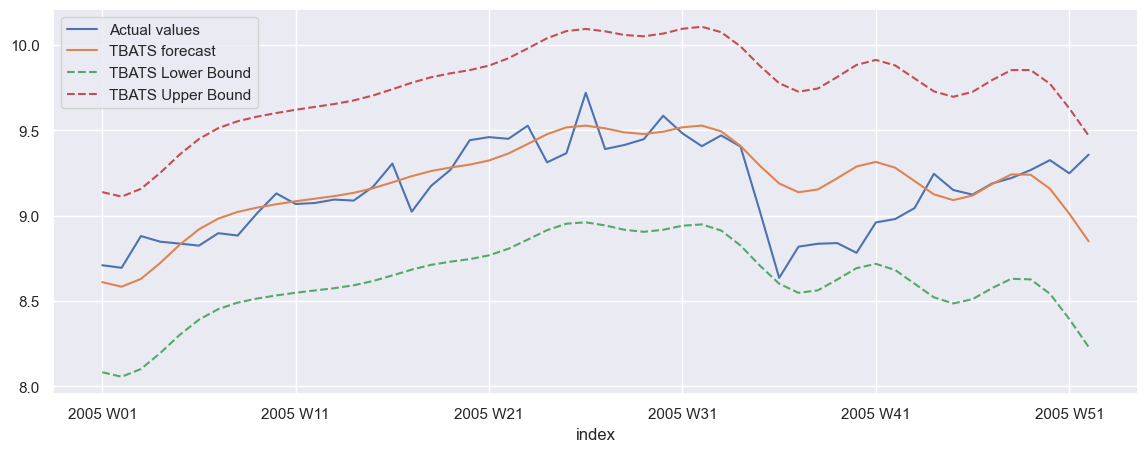

In [29]:
# Step 4: Generate forecasts and compare all methods

fitted_data, confidence_int_TBATS = fitted_model.forecast(steps=len(gas_test_2005), confidence_level = 0.95)
tbats_forecast = pd.DataFrame(data=fitted_data, index = index_2005)

# # Plot forecasts
combined_TBATS = pd.concat([gas_test_2005, tbats_forecast], axis = 1)
combined_TBATS.columns = ['Actual values','TBATS forecast']

# # Plot prediction interval
combined_TBATS['TBATS Lower Bound'] = confidence_int_TBATS['lower_bound'].tolist()
combined_TBATS['TBATS Upper Bound'] = confidence_int_TBATS['upper_bound'].tolist()
combined_TBATS.plot(style=['-', '-', '--', '--'])

In [ ]:
# Step 5: Calculate the percentage of actual values within the prediction interval

# CODE HERE

combined_TBATS['inside_conf'] = (combined_TBATS['Actual values'] <= combined_TBATS['TBATS Upper Bound']) & (combined_TBATS['Actual values'] >= combined_TBATS['TBATS Lower Bound'])
combined_ARIMA['inside_conf'] = (combined_ARIMA['Actual values'] <= combined_ARIMA['ARIMA Upper Bound']) & (combined_ARIMA['Actual values'] >= combined_ARIMA['ARIMA Lower Bound'])

percentage_in_interval_TBATS = combined_TBATS[combined_TBATS["inside_conf"]].shape[0] * 100 / combined_TBATS.shape[0]  
percentage_in_interval_ARIMA = combined_ARIMA[combined_ARIMA["inside_conf"]].shape[0] * 100 / combined_ARIMA.shape[0] 


100.0

In [35]:
# Step 6: Calculate the MAPE and MSIS of all methods and compare

# MAPE
# CODE HERE
MAPE_TBATS = mean_absolute_percentage_error(gas_test_2005.values,tbats_forecast.values)
MAPE_ARIMA = mean_absolute_percentage_error(gas_test_2005.values,arima_forecast.values)

# MSIS
MSIS_TBATS = calculate_MSIS(gas_train['value'], combined_TBATS[['TBATS Lower Bound', 'TBATS Upper Bound']].values, len(gas_test_2005), alpha = 0.05)
MSIS_ARIMA = calculate_MSIS(gas_train['value'], combined_ARIMA[['ARIMA Lower Bound', 'ARIMA Upper Bound']].values, len(gas_test_2005), alpha = 0.05)


## Optional deep dive: Kalman Filtering

In [36]:
# Prepare the necessary functions for Kalman Filtering
import scipy as sp

### Kalman Fitter ###
class KalmanFitter():
    def __init__(self) -> None:
        
        return

    def fit_kalman_filter(self, y):
        # Set parameter names
        par_names = ['beta', 'sigma_ksi', 'sigma_zeta', 'const_mu']

        # Optimize filter
        res_optimize = sp.optimize.minimize(self.loglikelihood_sv, 
                                            x0= (0.5,1,1,0),
                                            bounds = ((-1,1), (0,1e6), (0,1e6), (-10,10)), 
                                            args = (y), 
                                            method='Nelder-Mead', 
                                            tol=1e-6, 
                                            options = {'maxiter': 10_000}) 
        
        # Save optimal parameters
        params_optimized = pd.Series(dict(zip(par_names, res_optimize.x)))

        # Run filter with optimal parameters
        optimized_filter = self.evaluate_filter(res_optimize.x, y) 
        y_pred = pd.Series(np.block(optimized_filter['y_pred']).reshape(-1))
    
        return params_optimized, y_pred

    def set_system_matrices(self, params, y):
        '''
        This function puts the passed parameters in the standard state-space format.
        See KalmanFilter.
        '''

        # Put parameters in matrix form for the state space model
        beta = params[0]
        sigma_ksi = params[1] 
        sigma_zeta = params[2] 
        const_mu = params[3]
        
        
        Z = np.array([beta, 1]).reshape(1,2)
        T = np.array([  [beta, 1],
                        [0, 1   ]]).reshape(2,2)
        
        c = np.array([0, const_mu]).reshape(2,1)
        d = 0

        m = T.shape[0]
        H = sigma_ksi**2
        Q = np.array([  [sigma_ksi**2, 0            ],
                        [0,             sigma_zeta**2]]).reshape(2,2)
        
        R = np.eye(m)
        a_init = np.array([y[0], np.nanmean(y)]).reshape(2,1)
        P_init = np.diag([10e7]*m)

        return Z, T, a_init, P_init, H, Q, R , d, c

    def evaluate_filter(self, params, y):
        Z, T, a_init, P_init, H, Q, R , d, c = self.set_system_matrices(params,y)

        # Initialize Kalman filter
        KF = KalmanFilter(
            y=y,
            a_init=a_init,
            P_init=P_init,
            H=H,
            Q=Q,
            R=R,
            d=d,
            c=c
        )

        # Run the Kalman filter
        res_filter = KF.run_filter(Z=Z, T=T)

        return res_filter

    def loglikelihood_sv(self, params, y):
        # Evaluate the filter
        res_filter = self.evaluate_filter(params, y)

        v = res_filter["v"]
        F = res_filter["F"]

        T = len(v)
        n = len(v[0])
        sum_det_Ft = 0
        sum_vFv = 0 
        
        # Evaluate log likelihood
        for t in range(T):
            sum_det_Ft += np.log(np.linalg.det(F[t]))
            sum_vFv += (v[t].T)@np.linalg.inv(F[t])@(v[t])

        llh = ((-T*n/2)*np.log(2*np.pi) - (1/2)*sum_det_Ft - (1/2) * sum_vFv) / (n*T)
        return -1 * llh.squeeze() 
    
    
### Kalman class ###
class KalmanFilter:
    """
    This class implements a Kalman filter. We have:

    1) The observation equation:
        y_t = Z_t * alpha_t + eps_t
        eps_t ~ N(0, H_t)

    2) The state update equation:
        alpha_{t+1} = T_t * alpha_t + R_t * eta_t
        eta_t ~ N (0, Q_t)

    3) Initialization
        alpha_1 ~ N(a1, P1)

        Stationary      -> a1 = mean(y_t),  P1 = var(y_t)
        Non-stationary  -> a1 = 0,          P1 = 10e7

    NOTE:
        - Z_t, H_t, R_t and Q_t are non-stochastic but can be time varying matrices.
    """

    def __init__(self, y, a_init, P_init, H, Q, R, d=0, c=0):
        self.y = np.array(y)
        self.n = y.shape[0]
        self.a_init = np.array(a_init)
        self.P_init = np.array(P_init)

        # Make vector over time if not already
        self.H = self.as_vector_over_time(H)
        self.Q = self.as_vector_over_time(Q)
        self.R = self.as_vector_over_time(R)
        self.d = self.as_vector_over_time(d)
        self.c = self.as_vector_over_time(c)

        # Keep track of the procedures being ran
        self.smoother_ran = False
        self.filter_ran = False
        self.disturbance_smoother_ran = False

    def run_filter(self, Z, T):
        """
        Return a dictionary with:
            - v
            - F
            - K
            - a_pred (a_t)
            - a_filter (a_t|t)
            - P
        """
        result_dict = {key: "" for key in ["a_pred", "a_filter", "P", "v", "F", "K", "y_filter", "y_pred"]}

        # Initialization
        a_pred = [np.zeros(shape=self.a_init.shape) for i in range(self.n + 1)]
        a_pred[0] = self.a_init

        a_filtered = [np.zeros(shape=self.a_init.shape) for i in range(self.n)]

        P = [np.zeros(shape=self.P_init.shape) for i in range(self.n + 1)]
        P[0] = self.P_init

        F = [None] * self.n
        K = [None] * self.n
        v = [np.array([0]).reshape(1, 1) for i in range(self.n)]

        Z = self.as_vector_over_time(Z)
        T = self.as_vector_over_time(T)

        y_pred = np.zeros(len(self.y) + 1)
    
        for t in range(self.n):    
            yt = self.y[t].reshape(1, 1)

            # Prediction error
            v[t] = yt - Z[t] @ a_pred[t] - self.d[t]
            
            if yt.shape[0]>1: 
                nan_idx = np.where(np.isnan(yt))[0]
                if len(nan_idx) > 0:
                    v[t].squeeze()[nan_idx] = 0
            elif np.isnan(yt):
                v[t] = np.zeros(shape=v[t - 1].shape)

            # Prediction variance
            inf_mat = np.zeros(shape=(yt.shape[0], yt.shape[0]))
            if np.isnan(yt).any(): 
                nan_idx = np.where(np.isnan(yt))[0]
                inf_mat[nan_idx, :] = 10e7
                inf_mat[:, nan_idx] = 10e7

            F[t] = Z[t] @ P[t] @ Z[t].T + self.H[t] + inf_mat

            PZF1 = P[t] @ Z[t].T @ np.linalg.inv(F[t])
            K[t] = T[t] @ PZF1

            # Filtered and predicted a
            a_filtered[t] = a_pred[t] + PZF1 @ v[t]
            a_pred[t + 1] = T[t] @ a_filtered[t] + self.c[t] 

            # Enter Yt into the state, since this is known.
            # If nan -> use filtered yt
            if not np.isnan(yt):
                a_pred[t + 1][0][0] = yt.squeeze()
            else:    
                a_pred[t + 1][0][0] = Z[t]@a_filtered[t] + self.d[t]

            # Predict y_{t+1} given current information
            y_pred[t+1] = Z[t]@a_pred[t+1] + self.d[t]
            

            # Update variance
            P[t + 1] = (
                T[t] @ P[t] @ T[t].T
                + self.R[t] @ self.Q[t] @ self.R[t].T
                - K[t] @ F[t] @ K[t].T
            )
        


        result_dict["a_pred"] = a_pred
        result_dict["a_filter"] = a_filtered
        result_dict["P"] = P
        result_dict["v"] = v
        result_dict["F"] = F
        result_dict["K"] = K
        result_dict["y_filter"] = [Z[t]@af + self.d[t] for t,af in enumerate(a_filtered)]
        
        y_pred[0] = np.nan
        result_dict["y_pred"] = y_pred

        # Save all matrices in class
        self.Z = Z
        self.T = T
        self.a_pred = result_dict["a_pred"]
        self.a_filter = result_dict["a_filter"]
        self.P = result_dict["P"]
        self.v = result_dict["v"]
        self.F = result_dict["F"]
        self.K = result_dict["K"]

        self.results_filter = result_dict
        self.filter_ran = True

        return result_dict
    
    def as_vector_over_time(self, matrix):
        # If the 'matrix' is already a list of length n, this is not needed
        if type(matrix) == list and len(matrix) == self.n:
            return matrix

        # Return an error if the length is not good
        if type(matrix) == list and len(matrix) != self.n:
            raise ValueError("The vector of matrices needs to be of length n")

        if type(matrix) == np.ndarray and matrix.shape[0] == self.n:
            return matrix
        
        if type(matrix) == np.ndarray:
            return [matrix for i in range(self.n)]
        
        if (
            type(matrix) == int
            or type(matrix) == float
            or type(matrix) == np.float64
            or type(matrix) == np.int64
            or type(matrix) == np.int32
            or type(matrix) == np.float32
            or type(matrix) == np.int16
            or type(matrix) == np.float16
        ):
            return [np.array(matrix).reshape(1, 1) for i in range(self.n)]

        else:
            raise TypeError(
                f"matrix needs to be of type np.ndarray or list, type given: {type(matrix)}"
            )


### Model
We saw in the data that 
- There are AR, MA and Seasonal components
- There is a trend in the data

We will try to capture this with a very simple AR(1) model with a time-varying constant, measured as a random walk with drift.

$y_t = \beta y_{t-1} + \mu_t + \xi_t$

$\mu_t = \mu_{t-1} + C_{\mu} + \zeta_t$

Where:

$\xi_t \sim N(0, \sigma^2_{\xi})$ 

$\zeta_t \sim N(0, \sigma^2_{\zeta})$

The model is estimated with Kalman Filtering, where we define the system matrices as follows:

$Z_t = [\beta, 1]$

$\alpha_t = [y_{t-1}, \mu_t]'$

$d_t = 0$

$H_t = \sigma^2_{\xi}$

$T_t = \begin{bmatrix}
\beta & 1 \\
0 & 1
\end{bmatrix} $


$c_t = [0, C_{\mu}]'$

$R_t = I_2$

$\eta_t = [\xi_t, \zeta_t]'$

$Q_t = \begin{bmatrix}
\sigma^2_{\xi} & 0 \\
0 & \sigma^2_{\zeta}
\end{bmatrix}$





Check for yourself that this gives us our model! This structure has been set in the KalmanFitter class implemented above.
The model incorporates the AR time, and tries to model seasonality and trend in the $\mu_t$ term.
As we will see, this works very well in-sample, but misses dyamics for out-of-sample predictions.

In [37]:
### Optimize the filter
# We plug in observed values to train on, and nans for values we want to predict
kalman_data = np.array([*gas_train.values.reshape(-1),  #Observed
                        *([np.nan]*len(gas_test_2005))] #We want to predict this
                        )

filter = KalmanFitter()
params, y_pred_kalman = filter.fit_kalman_filter(y=kalman_data)

# Print and examine optimal parameters
# What do you conclude?
...


C:\Users\Administrator\AppData\Local\Temp\2\ipykernel_8028\3437024614.py:212: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_pred[t+1] = Z[t]@a_pred[t+1] + self.d[t]
C:\Users\Administrator\AppData\Local\Temp\2\ipykernel_8028\3437024614.py:209: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  a_pred[t + 1][0][0] = Z[t]@a_filtered[t] + self.d[t]


Ellipsis

In [39]:
params

beta         -0.501649
sigma_ksi     0.000000
sigma_zeta    0.342324
const_mu      0.005818
dtype: float64

In [ ]:
# Plot the predictions for y
plt.plot(y_pred_kalman)
plt.vlines(x = len(gas_train.values), ymin=5, ymax=10, color= 'black', linestyles='--')
plt.title("Predicted y values")
plt.show()

In [ ]:
# Define the MAPE
def MAPE(pred, true):
    return round(np.abs((pred - true)/true).mean(),6)

In [ ]:
# Get size of train and test set
n_train = len(gas_train.values)
n_test = len(gas_test_2005.values)

# In-sample forecasts
in_sample_arima_predictions = ...
in_sample_kalman_predictions = ...

# Generate forecasts oos
fitted_data, confidence_int_ARIMA = model.predict(n_periods = len(gas_test_2005), return_conf_int = True, alpha = 0.05)
arima_forecast = ...
kalman_forecasts = ...


# Plot in-sample forecasts
...

# Print the in-sample MAPEs
...


# Plot OOS forecasts
...


# Print the OOS MAPEs
...


